**INTRODUCCION**

El objetivo de este trabajo fue calcular la densidad espectral de potencia a partir de diferentes estimadores. Para esto se usaron cinco señales: una de electrocardiograma (ECG), una de fotopletismografía (PPG) y tres señales de audio. Los métodos utilizados fueron el periodograma, el método de Welch y el método de Blackman-Tukey. Luego de obtener la densidad espectral de potencia para cada uno de los métodos y graficarla, se compararon los diferentes resultados obtenidos.

La densidad espectral de potencia describe cómo se distribuye la potencia de una señal en sus distintas frecuencias. En este trabajo, los tres estimadores utilizados para calcularla fueron el periodograma, el método de Welch y el método de Blackman-Tukey.
El primero (el periodograma) consiste en calcular la autocorrelación de la señal y, a partir de esta, su Transformada Rápida de Fourier (FFT). Este estimador es asintóticamente insesgado; sin embargo, su varianza no tiende a cero cuando se aumenta el número de muestras, por lo cual no se puede considerar como un estimador consistente.

El método de Welch utiliza una lógica similar. Sin embargo, divide la señal de entrada original en K segmentos con un 50% de solapamiento entre ellos. Luego, aplica una ventana a cada segmento para disminuir la varianza, calcula el periodograma de cada uno de estos K segmentos y los promedia. Con esto logra disminuir la varianza con respecto al periodograma original, lo cual lo convierte en un estimador consistente. Sin embargo, hay que tener en cuenta el trade-off que trae esta mejora en la varianza, ya que al disminuir la longitud de los segmentos a los cuales se les calcula la FFT, empeora la resolución espectral. Por esto, hay que elegir un valor de K que disminuya suficientemente la varianza sin comprometer demasiado la resolución espectral.

Por su parte, el método de Blackman-Tukey trabaja aplicando una ventana en el dominio de los retardos (lag window). Lo que hace es calcular la autocorrelación de la señal original y luego aplicarle una ventana de longitud M, menor a la longitud de la señal, para atenuar los valores de los extremos. Estos valores son menos significativos y contienen más ruido, por lo que contribuyen al aumento de la varianza. Luego, calcula la FFT de la autocorrelación ventaneada, obteniendo un valor para la densidad espectral de potencia cuya varianza tiende a cero y cuya media tiende al valor real, por lo cual es un estimador asintóticamente insesgado y consistente.



**PROCEDIMIENTO**

En primer lugar, con el material provisto por la cátedra, se imporaron las señales a analizar: un ECG sin ruido, un PPG sin ruido y tres señales de sonido

Text(0.5, 1.0, 'audio: silbido')

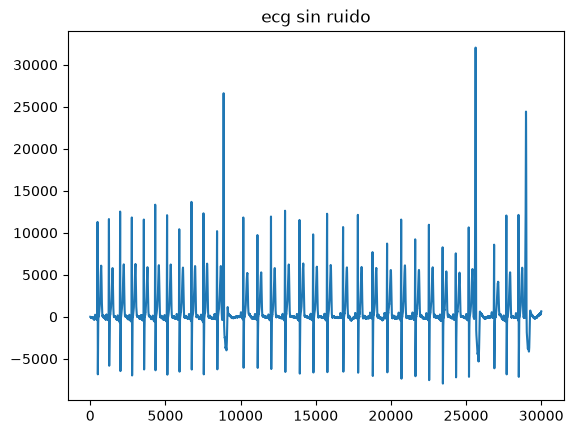

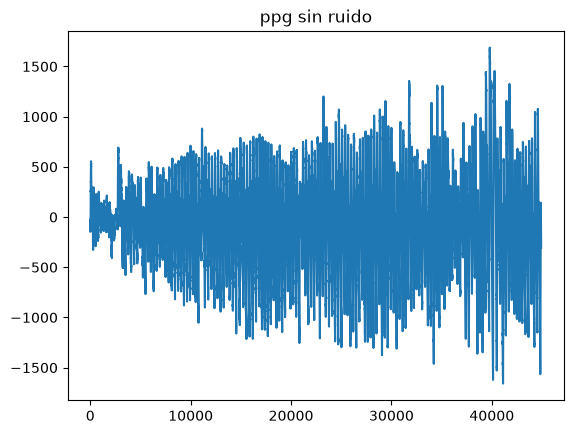

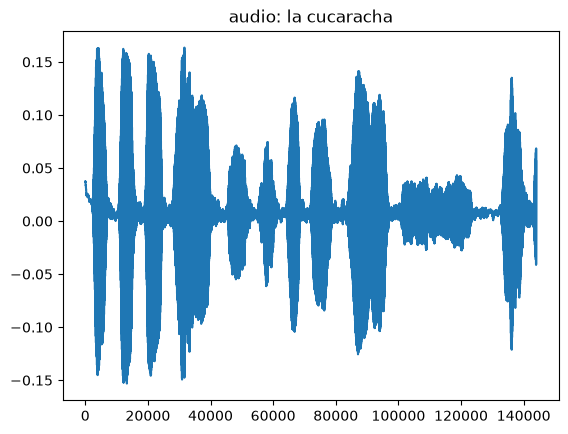

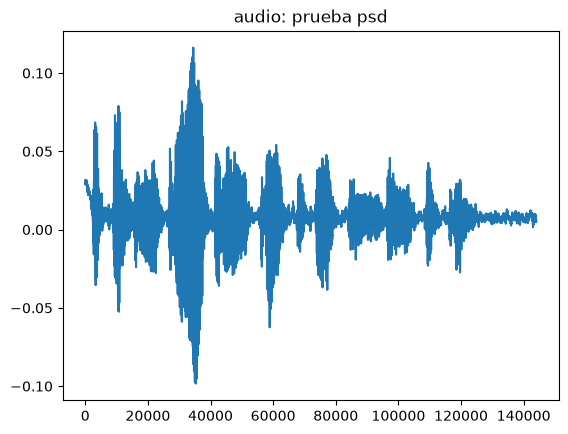

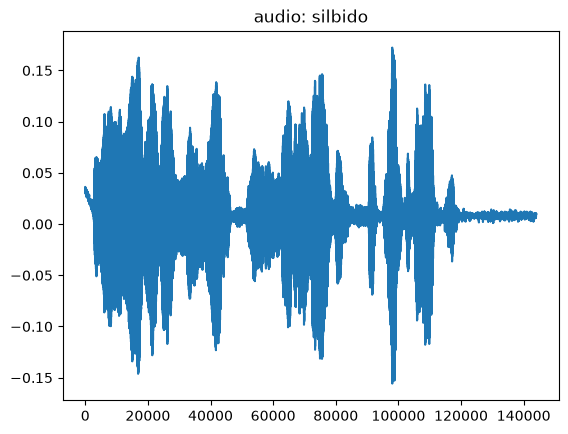

In [1]:
import numpy as np
from scipy import signal as sig

import matplotlib.pyplot as plt
   
import scipy.io as sio
from scipy.io.wavfile import write

##################
# Lectura de ECG #
##################

fs_ecg = 1000 # Hz

##################
## ECG sin ruido
##################

ecg_one_lead = np.load('ecg_sin_ruido.npy')

plt.figure()
plt.plot(ecg_one_lead)
plt.title("ecg sin ruido")

####################################
# Lectura de pletismografía (PPG)  #
####################################

fs_ppg = 400 # Hz

##################
## PPG sin ruido
##################

ppg = np.load('ppg_sin_ruido.npy')

plt.figure()
plt.plot(ppg)
plt.title("ppg sin ruido")

# ####################
# # Lectura de audio #
# ####################

# Cargar el archivo CSV como un array de NumPy
fs_audio, wav_data = sio.wavfile.read('la cucaracha.wav')
plt.figure()
plt.plot(wav_data)
plt.title("audio: la cucaracha")

fs_audio, wav_data = sio.wavfile.read('prueba psd.wav')
plt.figure()
plt.plot(wav_data)
plt.title("audio: prueba psd")

fs_audio, wav_data = sio.wavfile.read('silbido.wav')
plt.figure()
plt.plot(wav_data)
plt.title("audio: silbido")

Luego se definió una funcion para poder implementar el método de Blackman-Tukey, la cual toma la señal original, calcula su autocorrelación y ventanea la señal con una ventana Blackman de modo de eliminar los valores de sus extremos antes de calcular la PSD mediante la FFT

In [2]:
########################
#FUNCION BLACKMAN TUKEY

def blackman_tukey(x, fs, M=None):
    x = np.asarray(x).ravel() 
    x=x- np.mean(x)
    N = len(x)
    
    if M is None:
        M = N // 5
    M = max(1, M)
    
    m = M - 1
    r_len = 2 * M - 1
    
    # mode='full' da longitud 2N - 1
    r_full = np.correlate(x, x, mode='full')
    
    r = (r_full[N - 1 - m : N + m])/N
    
    w = sig.windows.blackman(r_len)
    
    R_windowed = r*w
    Px = np.abs(np.fft.fft(R_windowed, n=N))
    
    Px = Px / fs
    
    
    return Px

Para cada señal se definieron los tres estimadores correspondientes. Para el método de Welch y Blackman-Tukey primero se realizo un barrido de prueba de diferentes valores para el número de subsecuencias en el caso de Welch y para diferentes longitudes de ventana para Blackman-Tukey, con el fin de encontrar el valor más adecuado para el cual disminuye suficientemente la varianza sin comprometer la resolución espectral necesaria para un correco análisis de la señal. Esto es analizado posteriormente mediante los gráficos correspondientes

In [3]:
############################
#PERIDIOGRAMA PARA EL ECG

per_ECG=sig.periodogram(ecg_one_lead, fs_ecg, 'boxcar')

#WELCH PARA EL ECG

N=len(ecg_one_lead)
Lecg= np.array([N/15, N/20, N/25])
Kecg=N/Lecg
arrwelch_ECG=[]
for l in Lecg:
    welch_ECG = sig.welch(
        ecg_one_lead,
        fs_ecg,
        'boxcar',
        int(l),
        int(l/2),
        N
    )
    
    arrwelch_ECG.append(welch_ECG)
    
#BT PARA EL ECG
Mecg=np.array([N//5, N//7, N//9])
#me gusto N//9
arrbt_ECG=[]
freqs_ecg = np.fft.fftfreq(N, d=1/fs_ecg)[:N//2]
for m in Mecg:
    bt_ECG= blackman_tukey(ecg_one_lead, fs_ecg ,m)[:N//2]
    
    arrbt_ECG.append(bt_ECG)
###############################
#PERIDIOGRAMA PARA EL PPG

per_PPG=sig.periodogram(ppg, fs_ppg, 'boxcar')

#WELCH PARA EL PPG

N=len(ppg)
Lppg= np.array([N/5, N/6, N/7])
Kppg=N/Lppg
arrwelch_PPG=[]
for l in Lppg:
    welch_PPG = sig.welch(
        ppg,
        fs_ppg,
        'boxcar',
        int(l),
        int(l/2),
        N
    )
    
    arrwelch_PPG.append(welch_PPG)
    
#BT PARA EL PPG
Mppg=np.array([N//5, N//7, N//9])
#me gusto N//7
arrbt_PPG=[]
freqs_ppg = np.fft.fftfreq(N, d=1/fs_ppg)[:N//2]
for m in Mppg:
    bt_PPG= blackman_tukey(ppg, fs_ppg ,m)[:N//2]
    
    arrbt_PPG.append(bt_PPG)
    
################################
archivos_audio = ['la cucaracha.wav', 'prueba psd.wav', 'silbido.wav']

per_audio = {}
arrwelch_audio = {}
arrbt_audio = {}
freqs_audio = {}
Kaudio = {}
Maudio = {}
fs_audio_dict = {}

for archivo in archivos_audio:
    fs_audio, wav_data = sio.wavfile.read(archivo)
    wav_data = wav_data.astype(float)        
    if wav_data.ndim > 1:
        wav_data = wav_data[:, 0]               
    fs_audio_dict[archivo] = fs_audio

    per_audio[archivo] = sig.periodogram(wav_data, fs_audio, 'boxcar')

    N = len(wav_data)
    Lson = np.array([N/33, N/27, N/30])
    Kson = N/Lson
    Kaudio[archivo] = Kson

    arrwelch = []
    for l in Lson:
        welch_audio = sig.welch(wav_data, fs_audio, 'boxcar', int(l), int(l/2), N)
        arrwelch.append(welch_audio)
    arrwelch_audio[archivo] = arrwelch

    Mson = np.array([N//5, N//7, N//9])
    Maudio[archivo] = Mson
    freqs_audio[archivo] = np.fft.fftfreq(N, d=1/fs_audio)[:N//2]
    arrbt = []
    for m in Mson:
        bt = blackman_tukey(wav_data, fs_audio, m)[:N//2]
        arrbt.append(bt)
    arrbt_audio[archivo] = arrbt


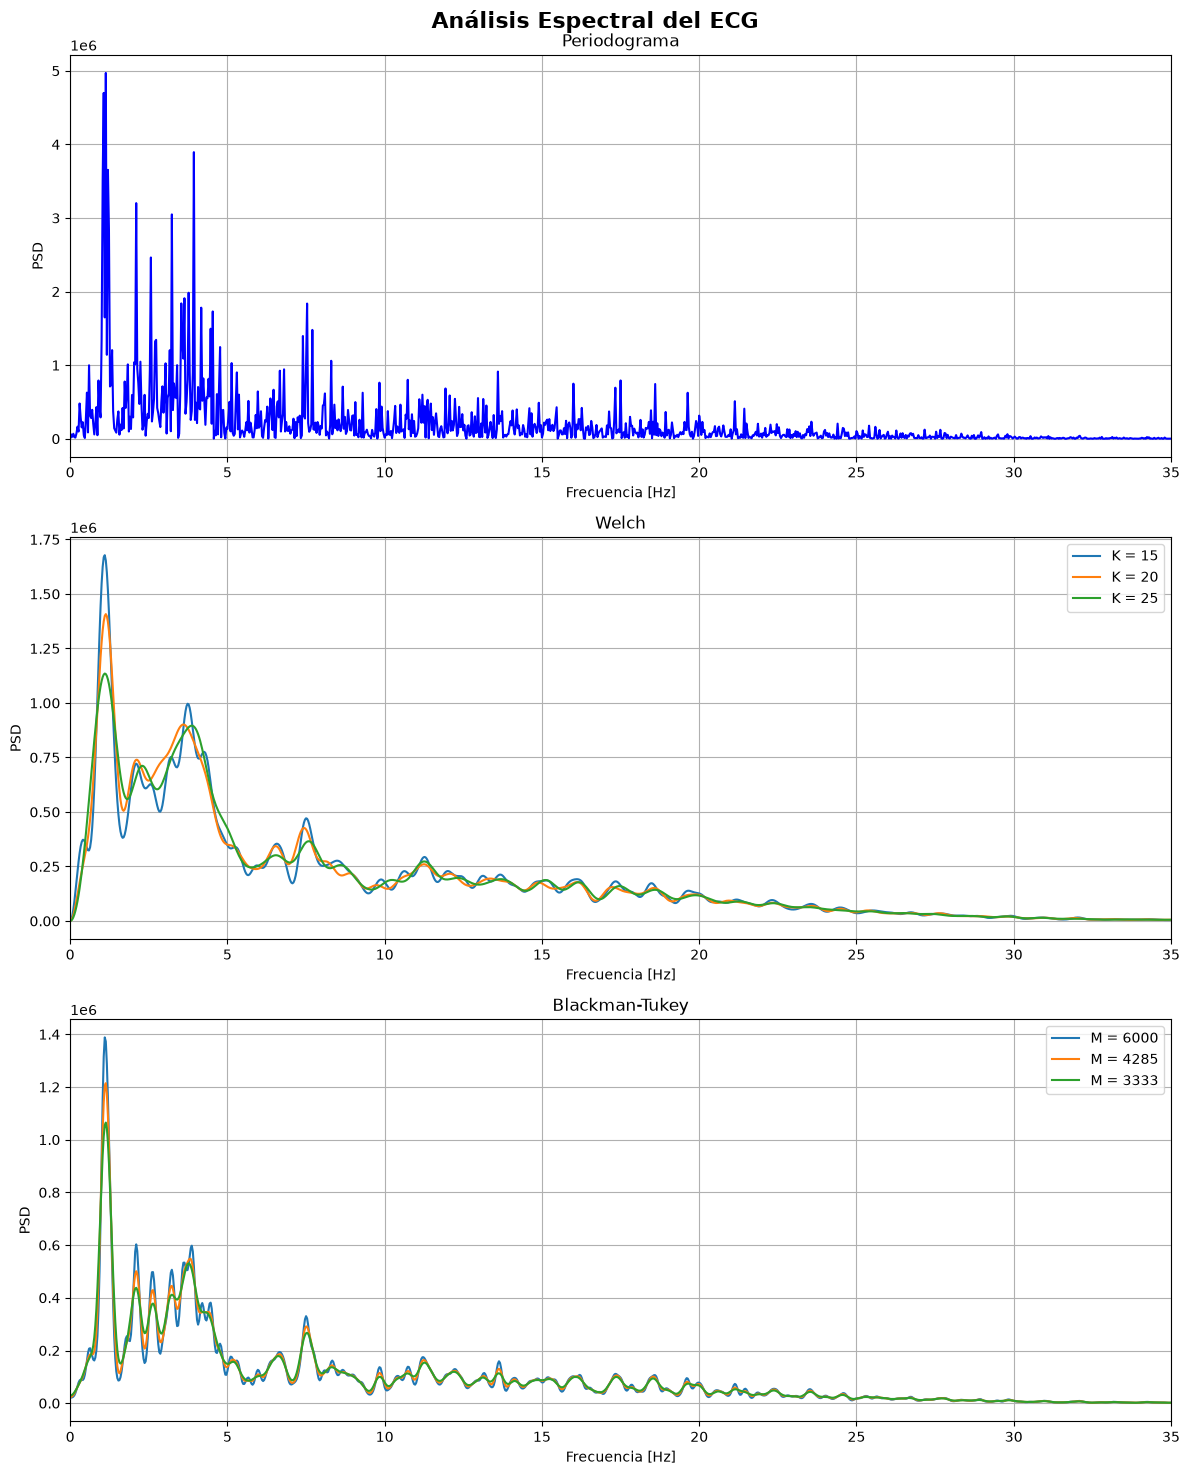

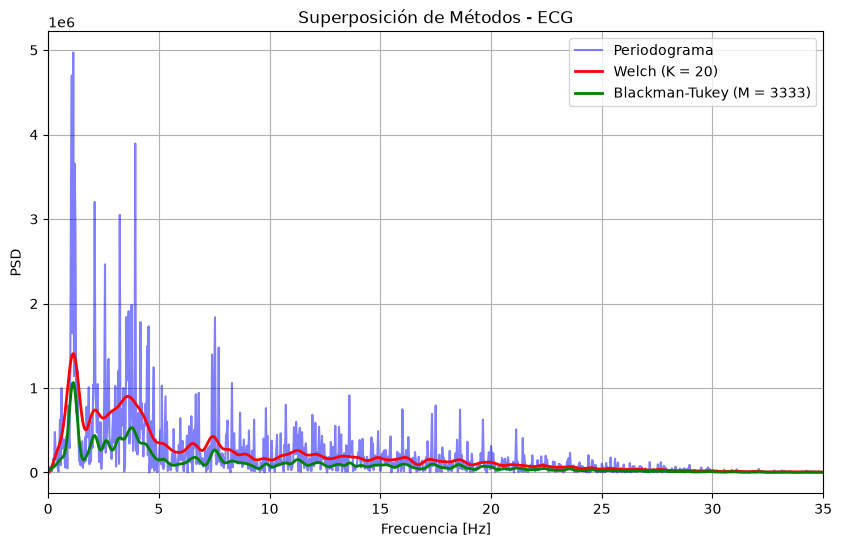

In [8]:
############################################
#GRÁFICOS PARA EL ECG 

fig_ecg, axs_ecg = plt.subplots(3, 1, figsize=(12, 15))
fig_ecg.suptitle('Análisis Espectral del ECG', fontsize=16, fontweight='bold')

# Periodograma ECG
axs_ecg[0].plot(per_ECG[0], per_ECG[1], color='blue')
axs_ecg[0].set_title('Periodograma')
axs_ecg[0].set_xlabel('Frecuencia [Hz]')
axs_ecg[0].set_ylabel('PSD')
axs_ecg[0].set_xlim(0, 35)  
axs_ecg[0].grid(True)

# Welch ECG (barrido para varios K)
for i in range(len(arrwelch_ECG)):
    axs_ecg[1].plot(arrwelch_ECG[i][0], arrwelch_ECG[i][1], label=f'K = {Kecg[i]:.0f}')
axs_ecg[1].set_title('Welch')
axs_ecg[1].set_xlabel('Frecuencia [Hz]')
axs_ecg[1].set_ylabel('PSD')
axs_ecg[1].set_xlim(0, 35)  
axs_ecg[1].legend()
axs_ecg[1].grid(True)

# Blackman-Tukey ECG (barrido para varios M)
for i in range(len(arrbt_ECG)):
    axs_ecg[2].plot(freqs_ecg, arrbt_ECG[i], label=f'M = {Mecg[i]:.0f}')
axs_ecg[2].set_title('Blackman-Tukey')
axs_ecg[2].set_xlabel('Frecuencia [Hz]')
axs_ecg[2].set_ylabel('PSD')
axs_ecg[2].set_xlim(0, 35)  
axs_ecg[2].legend()
axs_ecg[2].grid(True)

plt.tight_layout() 
plt.show()

#################################
#GRÁFICO SUPERPUESTO PARA EL ECG

plt.figure(figsize=(10, 6))
plt.title('Superposición de Métodos - ECG')

# Periodograma
plt.plot(per_ECG[0], per_ECG[1], label='Periodograma', color='blue', alpha=0.5)

# Welch
plt.plot(arrwelch_ECG[1][0], arrwelch_ECG[1][1], 
         label=f'Welch (K = {Kecg[1]:.0f})', color='red', linewidth=2)

# Blackman-Tukey 
plt.plot(freqs_ecg, arrbt_ECG[2], 
         label=f'Blackman-Tukey (M = {Mecg[2]:.0f})', color='green', linewidth=2)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD')
plt.xlim(0, 35) 
plt.legend()
plt.grid(True)
plt.show()

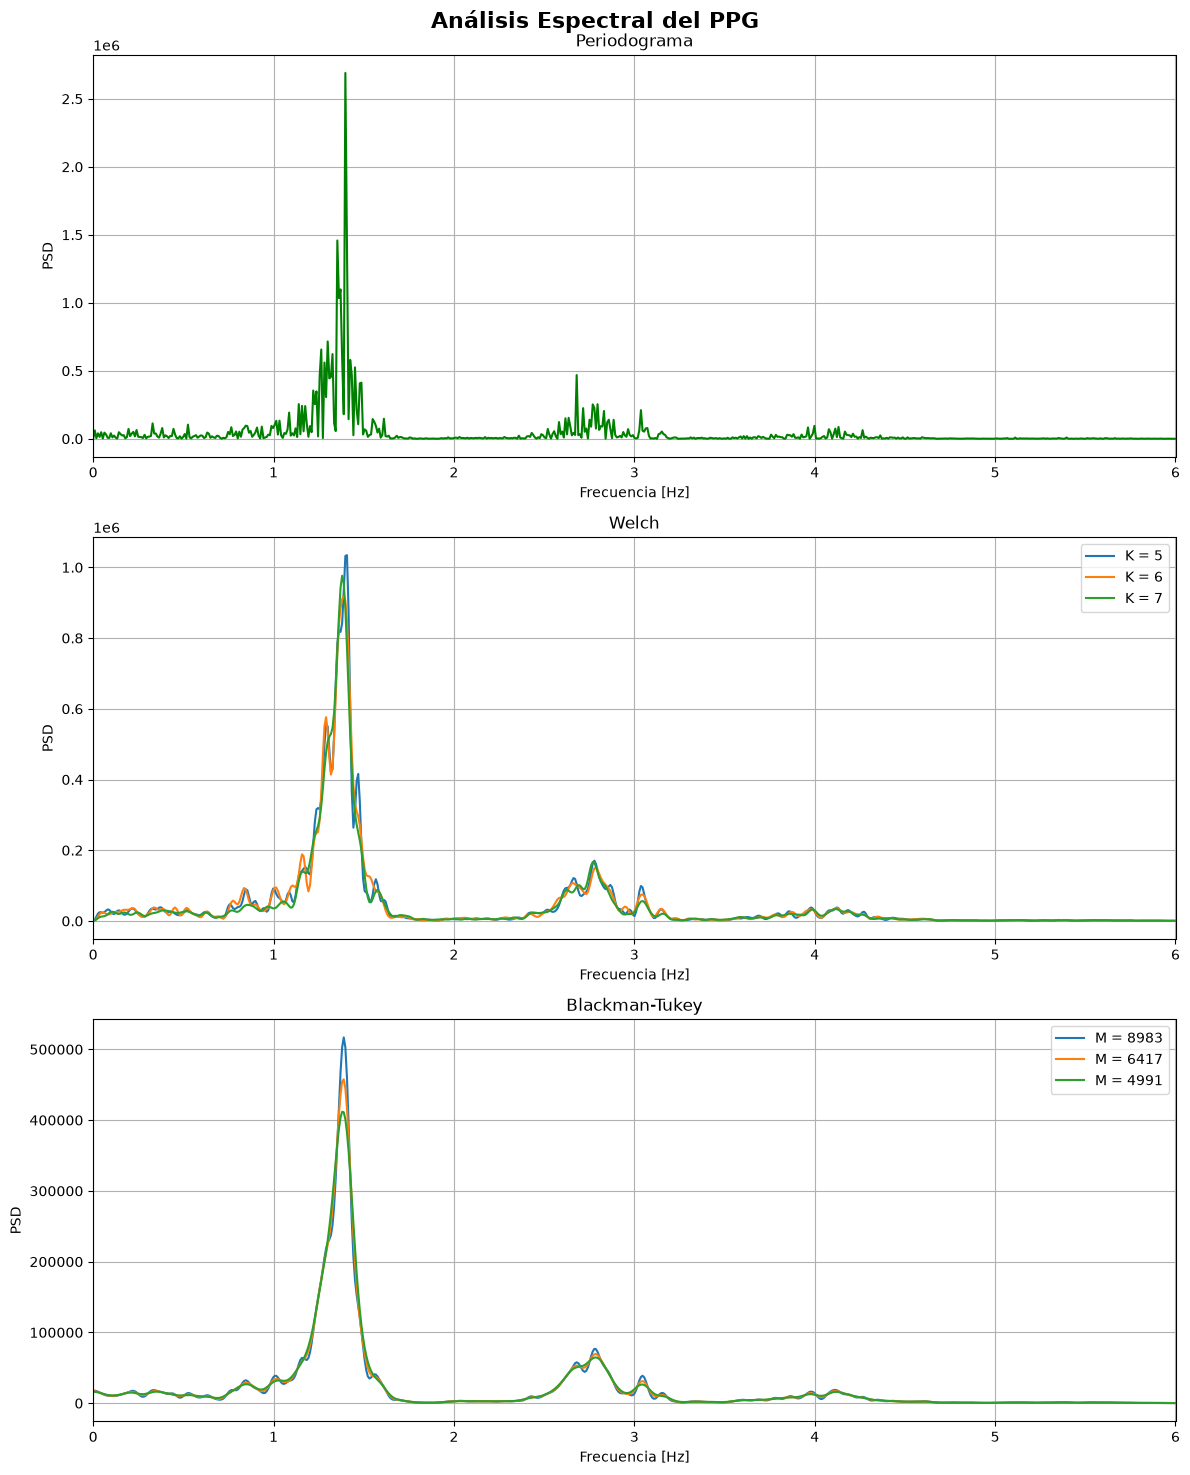

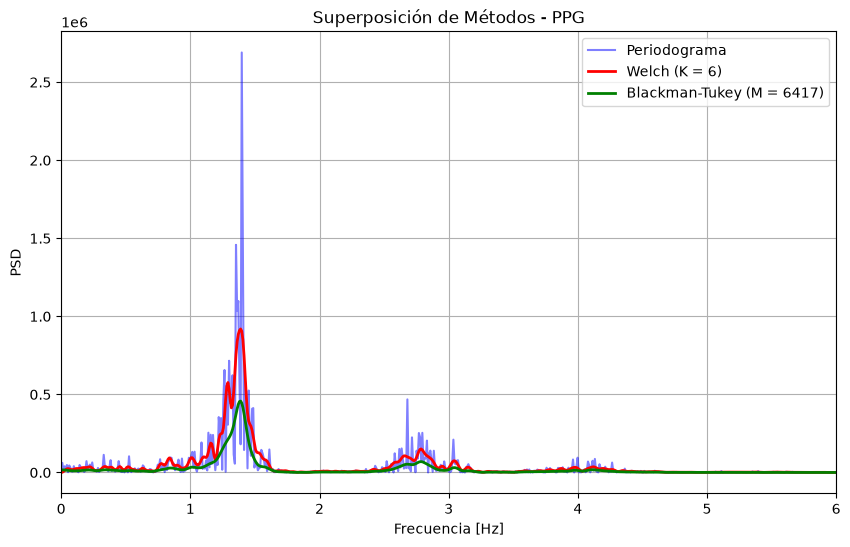

In [9]:
###########################
#GRÁFICOS PARA EL PPG 

fig_ppg, axs_ppg = plt.subplots(3, 1, figsize=(12, 15))
fig_ppg.suptitle('Análisis Espectral del PPG', fontsize=16, fontweight='bold')

# Periodograma PPG
axs_ppg[0].plot(per_PPG[0], per_PPG[1], color='green')
axs_ppg[0].set_title('Periodograma')
axs_ppg[0].set_xlabel('Frecuencia [Hz]')
axs_ppg[0].set_ylabel('PSD')
axs_ppg[0].set_xlim(0, 6) 
axs_ppg[0].grid(True)

# Welch PPG (barrido para varios K)
for i in range(len(arrwelch_PPG)):
    axs_ppg[1].plot(arrwelch_PPG[i][0], arrwelch_PPG[i][1], label=f'K = {Kppg[i]:.0f}')
axs_ppg[1].set_title('Welch')
axs_ppg[1].set_xlabel('Frecuencia [Hz]')
axs_ppg[1].set_ylabel('PSD')
axs_ppg[1].set_xlim(0, 6)  
axs_ppg[1].legend()
axs_ppg[1].grid(True)

# Blackman-Tukey PPG (barrido para varios M)
for i in range(len(arrbt_PPG)):
    axs_ppg[2].plot(freqs_ppg, arrbt_PPG[i], label=f'M = {Mppg[i]:.0f}')
axs_ppg[2].set_title('Blackman-Tukey')
axs_ppg[2].set_xlabel('Frecuencia [Hz]')
axs_ppg[2].set_ylabel('PSD')
axs_ppg[2].set_xlim(0, 6)  # Zoom solicitado
axs_ppg[2].legend()
axs_ppg[2].grid(True)

plt.tight_layout()
plt.show()

#################################
#GRÁFICO SUPERPUESTO PARA EL PPG
plt.figure(figsize=(10, 6))
plt.title('Superposición de Métodos - PPG')

# Periodograma
plt.plot(per_PPG[0], per_PPG[1], label='Periodograma', color='blue', alpha=0.5)

# Welch 
plt.plot(arrwelch_PPG[1][0], arrwelch_PPG[1][1], 
         label=f'Welch (K = {Kppg[1]:.0f})', color='red', linewidth=2)

# Blackman-Tukey 
plt.plot(freqs_ppg, arrbt_PPG[1], 
         label=f'Blackman-Tukey (M = {Mppg[1]:.0f})', color='green', linewidth=2)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD')
plt.xlim(0, 6)  
plt.legend()
plt.grid(True)
plt.show()

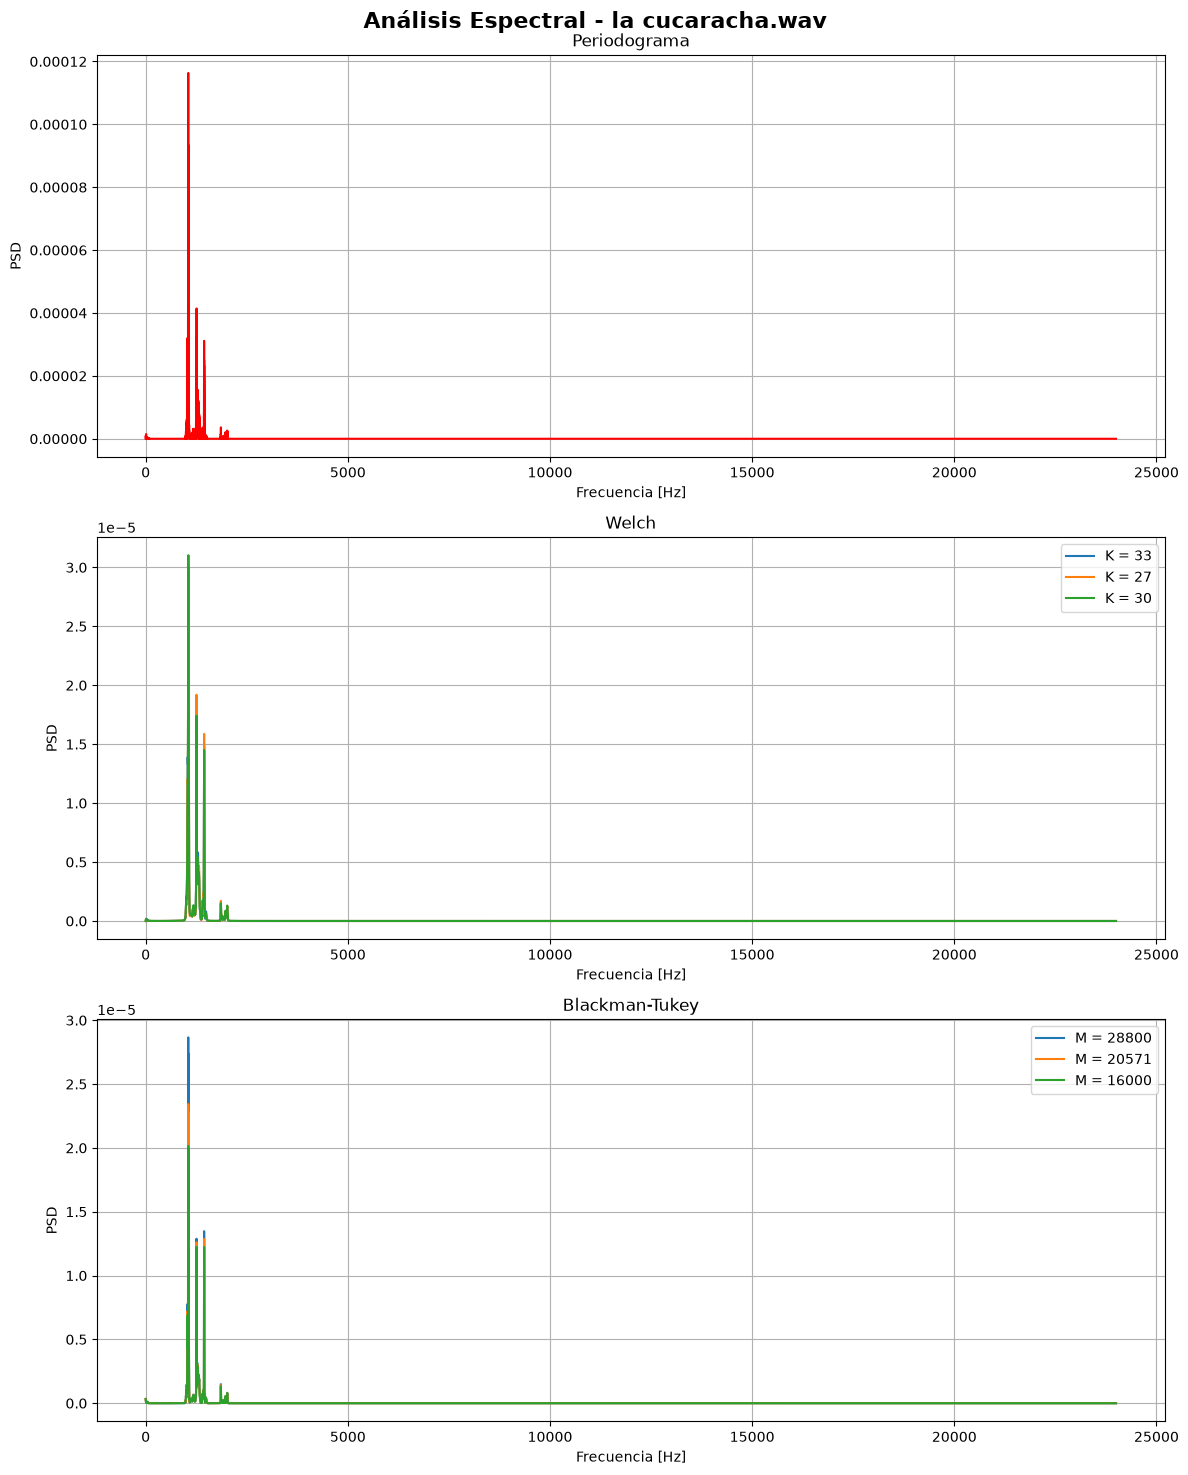

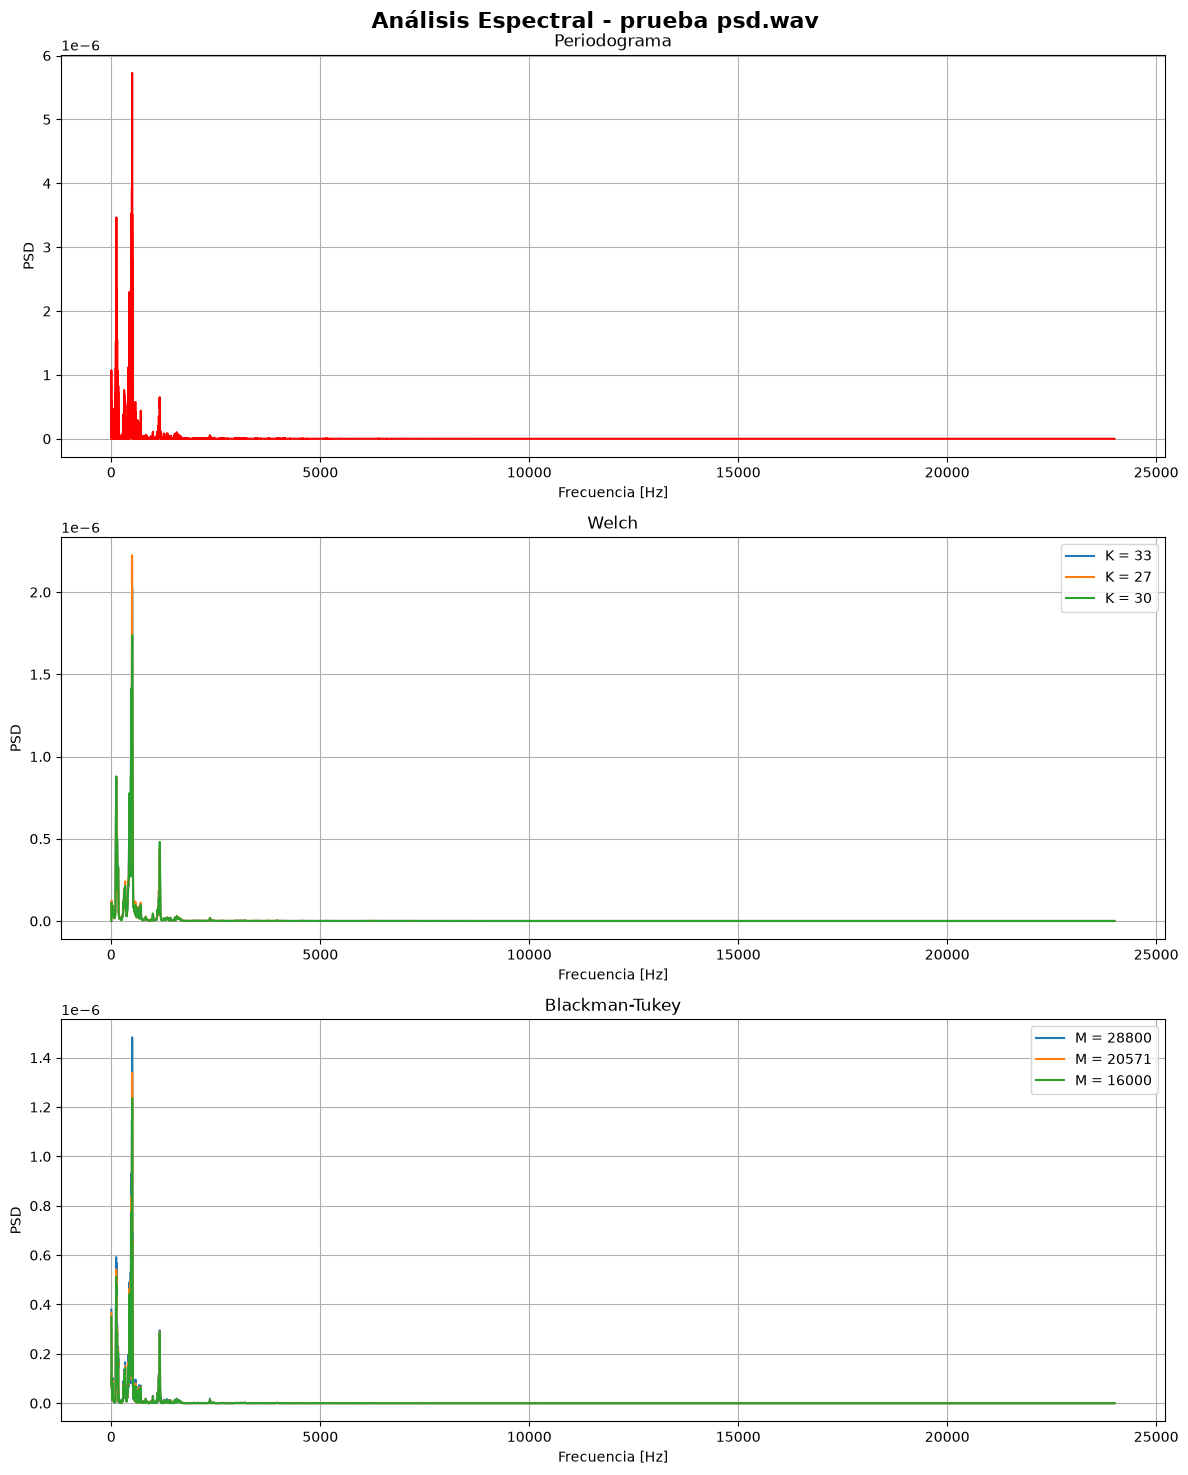

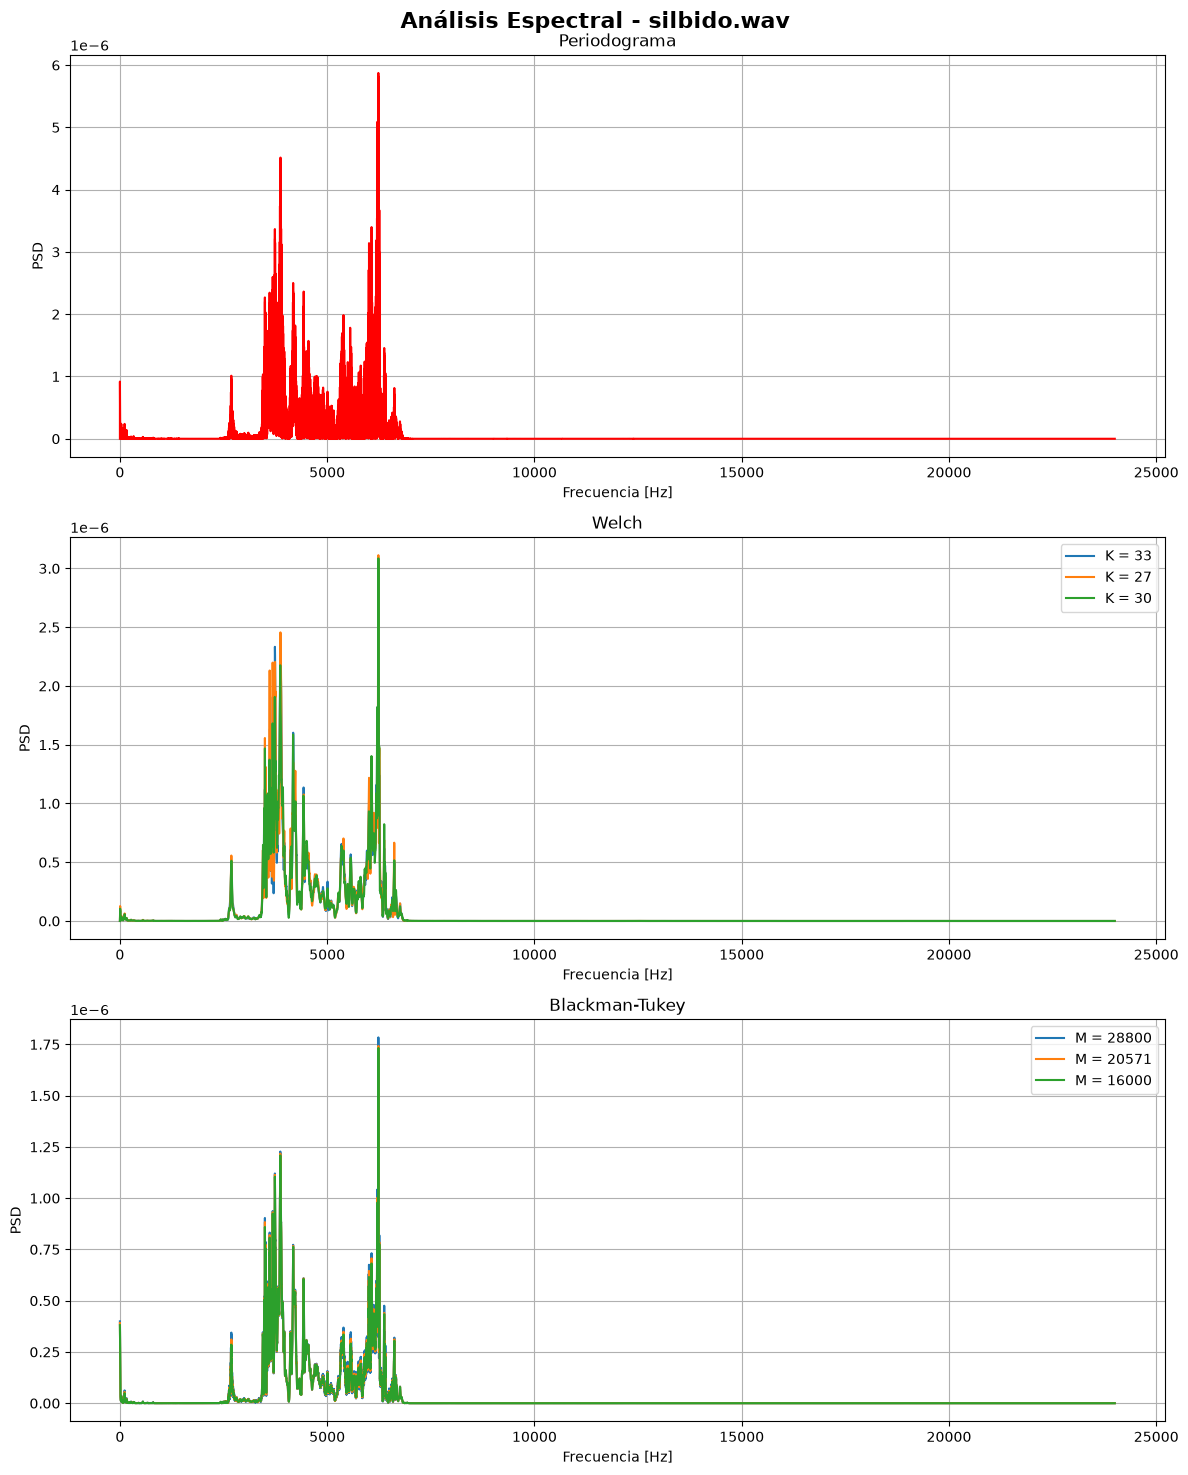

In [10]:
####################################### 
# graficos para los sonidos 

for archivo in archivos_audio:
    fig_son, axs_son = plt.subplots(3, 1, figsize=(12, 15))
    fig_son.suptitle(f'Análisis Espectral - {archivo}', fontsize=16, fontweight='bold')

    f_per, Pxx_per = per_audio[archivo]
    axs_son[0].plot(f_per, Pxx_per, color='red')
    axs_son[0].set_title('Periodograma')
    axs_son[0].set_xlabel('Frecuencia [Hz]')
    axs_son[0].set_ylabel('PSD')
    axs_son[0].grid(True)

    for i in range(len(arrwelch_audio[archivo])):
        axs_son[1].plot(arrwelch_audio[archivo][i][0], arrwelch_audio[archivo][i][1],
                         label=f'K = {Kaudio[archivo][i]:.0f}')
    axs_son[1].set_title('Welch')
    axs_son[1].set_xlabel('Frecuencia [Hz]')
    axs_son[1].set_ylabel('PSD')
    axs_son[1].legend()
    axs_son[1].grid(True)

    for i in range(len(arrbt_audio[archivo])):
        axs_son[2].plot(freqs_audio[archivo], arrbt_audio[archivo][i],
                         label=f'M = {Maudio[archivo][i]:.0f}')
    axs_son[2].set_title('Blackman-Tukey')
    axs_son[2].set_xlabel('Frecuencia [Hz]')
    axs_son[2].set_ylabel('PSD')
    axs_son[2].legend()
    axs_son[2].grid(True)

    plt.tight_layout()
    plt.show()

In [11]:

def ancho_de_banda(f, Pxx, frac=0.99):
    df = f[1] - f[0]
    potencia_acumulada = np.cumsum(Pxx) * df
    potencia_acumulada /= potencia_acumulada[-1]
    idx = np.searchsorted(potencia_acumulada, frac)
    return f[idx]

resultados_bw = []


f, Pxx = arrwelch_ECG[1]
resultados_bw.append({'Señal': 'ECG', 'fs [Hz]': fs_ecg,
                       'BW 95% [Hz]': ancho_de_banda(f, Pxx, 0.95),
                       'BW 99% [Hz]': ancho_de_banda(f, Pxx, 0.99)})


f, Pxx = arrwelch_PPG[1]
resultados_bw.append({'Señal': 'PPG', 'fs [Hz]': fs_ppg,
                       'BW 95% [Hz]': ancho_de_banda(f, Pxx, 0.95),
                       'BW 99% [Hz]': ancho_de_banda(f, Pxx, 0.99)})


for archivo in archivos_audio:
    f, Pxx = arrwelch_audio[archivo][1]
    resultados_bw.append({'Señal': archivo, 'fs [Hz]': fs_audio_dict[archivo],
                           'BW 95% [Hz]': ancho_de_banda(f, Pxx, 0.95),
                           'BW 99% [Hz]': ancho_de_banda(f, Pxx, 0.99)})



print("RESULTADOS DE ANCHO DE BANDA ")

formato = "{:<20} | {:<10} | {:<12} | {:<12}"

print(formato.format("Señal", "fs [Hz]", "BW 95% [Hz]", "BW 99% [Hz]"))

for res in resultados_bw:
    print(formato.format(
        str(res['Señal'])[:20],       
        res['fs [Hz]'],               
        f"{res['BW 95% [Hz]']:.2f}", 
        f"{res['BW 99% [Hz]']:.2f}"  
    ))



RESULTADOS DE ANCHO DE BANDA 
Señal                | fs [Hz]    | BW 95% [Hz]  | BW 99% [Hz] 
ECG                  | 1000       | 23.23        | 32.80       
PPG                  | 400        | 3.99         | 5.69        
la cucaracha.wav     | 48000      | 1499.33      | 2015.00     
prueba psd.wav       | 48000      | 1181.67      | 2635.67     
silbido.wav          | 48000      | 6294.67      | 6651.67     


**RESULTADOS Y ANÁLISIS**

***Para el ECG:***

**Decición sobre los valores de K y M:**

Para el método de Welch un K=20, ya que para este valor se puede observar graficamente como se preserva la información relevante y se disminuye la varianza. Además para este valor, como $L = \frac{30000}{20} = 1500 $, entonces $\Delta f = \frac{fs}{1500} = \frac{2}{3} Hz$. Esto permiete una buena resolución espectral y una disminución de varianza adecuado, conviryiendolo en un estimador conssitente.

Análogamente, para el método de Blackman-Tukey, se eligió $M= \frac{N}{9}$, de forma tal que $\Delta f = \frac{fs}{3333} = 0.3 Hz$. Esto permitió una resolucón espectral aun mayor que para el método de Welch en este caso y una reducción de varianza acorde

**Comparación entre métodos**

En primer lugar, el Periodograma muestra un espectro muy ruidoso, dificultando la identificación precisa de armónicos secundarios debido a la alta varianza. Por su parte, el método de Welch suaviza la curva, permitiendo identificar claramente el pico dominante de la frecuencia cardíaca y sus armónicos. La estimación por Autocorrelación con Blackman también mejora la PSD , eliminando gran parte del ruido de fondo manteniendo una buena definición de los picos principales gracias a la supresión de lóbulos laterales de la ventana.

***Para el PPG:***

**Decisión sobre los valores de K y M:**

Para el método de Welch se eligió K=6, ya que preserva la estructura armónica de la señal sin agregar varianza excesiva. Con N≈44920 y fs=400 Hz, $L = \frac{44920}{6} \approx 7487$, por lo que $\Delta f = \frac{fs}{L} \approx 0.053$ Hz. Para Blackman-Tukey se eligió M=N/7≈6417, dando una resolución algo mayor sin perder la forma de los picos.

A diferencia del ECG, el PPG muestra un espectro mucho más concentrado: un pico dominante alrededor de 1.4 Hz (la frecuencia cardíaca?) y armónicos claros en aproximadamente 2.7 Hz y 4.1 Hz. Esto es esperable, ya que la onda de pulso PPG no es sinusoidal , por lo que su descomposición de Fourier concentra energía en la fundamental y sus primeros armónicos en vez de repartirse en un ancho de banda continuo como el ECG. Welch y Blackman-Tukey suavizan el ruido del periodograma sin borrar esta estructura armónica, porque los picos son mucho más grandes que la varianza del piso de ruido.

**Para las señales de audio**

*la cucaracha.wav:* Al ser una señal de audio musical o vocal, la mayor parte de su energía se encuentra en las bajas y medias frecuencias. El 95% de su potencia está concentrada por debajo de los 1.5kHz

*prueba psd.wav:* Presenta un ancho de banda al 95% (1181.67 Hz) incluso más angosto que el de la cucaracha, pero un ancho de banda al 99% notablemente mayor (2635.67 Hz). Esto indica que la mayor parte de la energía está concentrada en una banda algo más angosta que la de la cucaracha, pero con una cola de alta frecuencia más larga: sugiere la presencia de armónicos agudos, sibilantes o ruido de fondo de mayor frecuencia que en la otra grabación de voz.

*silbido.wav:* Es una señal de alta frecuencia . Su energía no está concentrada en los graves; el 95% de su potencia se alcanza recién cerca de los 6.3kHz y el 99% en 6.65kHz

Los gráficos espectrales muestran picos muy marcados donde el método de Welch es excelente para resaltar el tono fundamental por encima del ruido de fondo, a diferencia del periodograma que ensuciaría la visualización.

**Análisis del ancho de banda**

En base a estos resultados, se puede observar cómo el PPG es la señal con menor ancho de banda de las cinco analizadas (3.99–5.69 Hz), seguida por el ECG (23.23–32.80 Hz). Ambos valores son coherentes con señales biológicas de este tipo: el monitoreo de ECG suele considerarse limitado a un rango de entre 0.5 y 40 Hz, y el PPG, al ser una onda de pulso más suave, concentra su energía en un rango aún más angosto.

Comparando ambos grupos, se observa una diferencia de más de dos órdenes de magnitud entre las señales biológicas y las de audio, lo cual tiene sentido físico: el ECG y el PPG son procesos fisiológicos lentos, mientras que el audio necesita cubrir el rango audible.


**CONCLUSIÓN**

A partir del análisis de las cinco señales se pudo comparar el comportamiento de los tres estimadores de densidad espectral de potencia estudiados. El periodograma, si bien tiene la mejor resolución espectral posible, es en todos los casos el más ruidoso, confirmando lo esperado teóricamente: al no ser un estimador consistente, su varianza no decrece al aumentar la cantidad de muestras. Tanto Welch como Blackman-Tukey lograron reducir  esa varianza a costa de resolución espectral, permitiendo en ambos casos identificar con claridad el contenido espectral de interés de cada señal . La elección puntual de K (Welch) y M (Blackman-Tukey) en cada caso resultó un compromiso entre resolución y varianza específico de la señal analizada.

El análisis del ancho de banda permitió cuantificar la diferencia en frecuencia entre los tipos de señales: las señales biológicas concentran su energía en un rango de frecuencias muy inferior al de las señales de audio. Dentro de las señales biológicas, el PPG mostró el ancho de banda más angosto de las cinco señales analizadas, lo ual tiene sentido al tratarse de una onda de pulso suave ; el ECG, en cambio, requiere un rango algo mayor para representar con fidelidad los procesos analizados en el.

Entre las señales de audio, la comparación entre el ancho de banda al 95% y al 99% resultó una herramienta útil para caracterizar la forma del espectro más allá del valor absoluto del ancho de banda: una brecha pequeña entre ambos umbrales (como la del silbido) concentra un unico tono en una banda angosta, mientras que una diferencia mayor (como la de las señales de voz) refleja un espectro más distribuido.

En conjunto, el trabajo permitió verificar de forma práctica el compromiso sesgo-varianza-resolución  en la estimación espectral no paramétrica, y cómo la elección del estimador y de sus parámetros debe adaptarse a las características particulares de cada tipo de señal.